In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print(df.head())
print("Dataset shape:", df.shape)
print(df.isnull().sum().sum())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [4]:
df = df.drop_duplicates()
df = df.dropna()

X = df.drop("quality", axis=1)
y = (df["quality"] >= 6).astype(int)

print("Missing values:", df.isnull().sum().sum())
print("Features shape:", X.shape)
print("Target classes:")
print(y.value_counts())

Missing values: 0
Features shape: (1359, 11)
Target classes:
quality
1    719
0    640
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (1087, 11)
Testing data: (272, 11)


In [6]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train_scaled.shape[1])
print("PCA components:", pca.n_components_)
print("Variance retained:", pca.explained_variance_ratio_.sum())

Original features: 11
PCA components: 9
Variance retained: 0.9778242937779074


In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB()
}

for name, model in models.items():
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    print(name, "Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Logistic Regression Accuracy: 0.7316
K-Nearest Neighbors Accuracy: 0.6875
Naive Bayes Accuracy: 0.75


## Conclusion

In this assignment, I used the Wine Quality dataset to perform dimensionality reduction and compare three classification algorithms.

I cleaned the dataset, removed duplicate rows, handled missing values, and applied Standard Scaling. Using PCA, I reduced the original 11 features to 9 components while retaining 97.78% of the variance.

I trained Logistic Regression, K-Nearest Neighbors (KNN), and Naive Bayes models. I compared their performance using Accuracy, Precision, Recall, and F1 Score.

Naive Bayes performed best, achieving 75% accuracy and an F1 score of 0.7687. Therefore, Naive Bayes was the best-performing model among the three models tested on this dataset.

This assignment helped me understand PCA, dimensionality reduction, and classification model evaluation.

In [8]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_pca)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.7316     0.7554  0.7292    0.7420
1  K-Nearest Neighbors    0.6875     0.6954  0.7292    0.7119
2          Naive Bayes    0.7500     0.7533  0.7847    0.7687


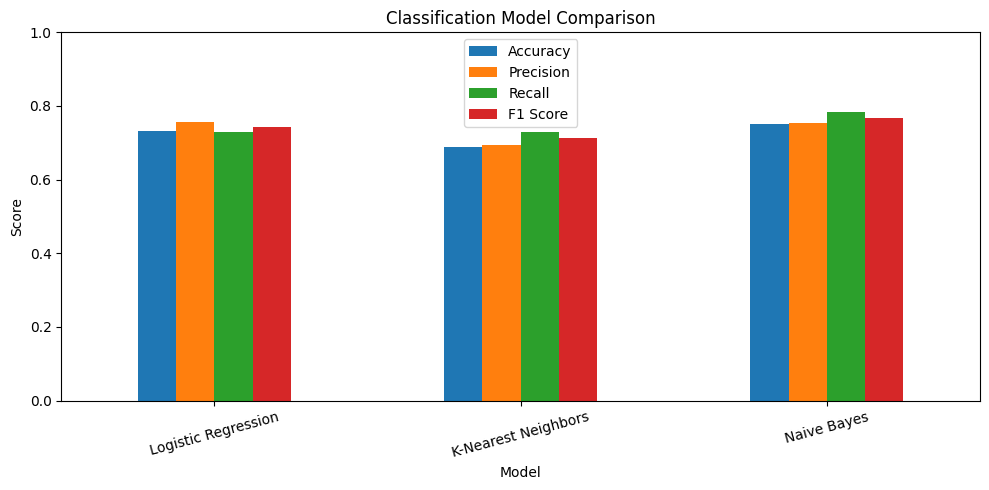

In [9]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()